# Passive Fail Slow Diagnosis in Disaggregated LLM Inference
**Siddharth V H · CS24MTECH15022**

Identify slow prefill workers, decode workers and KV-transfer paths by comparing service time with the work performed. Report a diagnosis when evidence is sufficient and **unknown** otherwise.

This prototype uses CPU-based simulation. Real LLM experiments and monitoring-overhead measurements are planned on SageMaker.



In [1]:
# Optional setup. Uncomment only if your kernel lacks these packages.
# %pip install "numpy>=1.24,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.7,<4" ipykernel
# The delivered outputs were tested with the versions printed below.
%matplotlib inline

## 1 Configuration

The simulated system has two prefill workers, two decode workers and four logical transfer paths. Logical paths may share physical resources in a real deployment.

TTFT is time to first token; ITL is the gap between tokens. SLOs define the latency targets.

- Evaluate a 30-second window every 10 seconds.
- Require two consecutive threshold exceedances, at least five supported requests and 80% supported operation records per component.
- Flag an SLO breach when more than 1% of TTFT values exceed 300 ms or ITL gaps exceed 100 ms, with sufficient samples.

These are prototype settings; real deployment targets require calibration.


In [2]:
from dataclasses import dataclass, asdict
from pathlib import Path
import copy, hashlib, json, platform, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Markdown
from sklearn.ensemble import GradientBoostingRegressor
import sklearn

@dataclass(frozen=True)
class Settings:
    seed: int = 20261009
    duration_s: float = 180.0
    window_s: float = 30.0
    cadence_s: float = 10.0
    persistence: int = 2
    min_requests: int = 5
    min_slo_requests: int = 10
    min_itl_gaps: int = 30
    min_support_fraction: float = 0.80
    scale_floor: float = 0.08
    component_scale_floor: float = 0.025
    threshold_quantile: float = 0.99
    ttft_slo_ms: float = 300.0
    itl_slo_ms: float = 100.0
    allowed_violation_fraction: float = 0.01
    model_rows_per_stage: int = 6000
    trees: int = 60

CFG = Settings()
STAGES = ('prefill', 'transfer', 'decode')
COMPONENTS = {'prefill': ('p1','p2'),
              'transfer': ('l11','l12','l21','l22'), 'decode': ('d1','d2')}
ALL_COMPONENTS = tuple(c for stage in STAGES for c in COMPONENTS[stage])
FEATURES = {'prefill': ['prompt_tokens','uncached_tokens','batch_size'],
            'transfer': ['kv_bytes'],
            'decode': ['context_tokens','batch_size','generated_so_far']}
METHODS = ('conditioned', 'historical', 'work_rate', 'matched_peer')
CONFIG_ID = 'synthetic-v1'
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'font.size': 10})
display(pd.Series({k:str(v) for k,v in asdict(CFG).items()}, name='Prototype settings').to_frame())
print(f'Python {platform.python_version()} | NumPy {np.__version__} | '
      f'pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

,Prototype settings
seed,20261009
duration_s,180.0
window_s,30.0
cadence_s,10.0
persistence,2
min_requests,5
min_slo_requests,10
min_itl_gaps,30
min_support_fraction,0.8
scale_floor,0.08


Python 3.12.14 | NumPy 2.3.5 | pandas 2.2.3 | scikit-learn 1.8.0


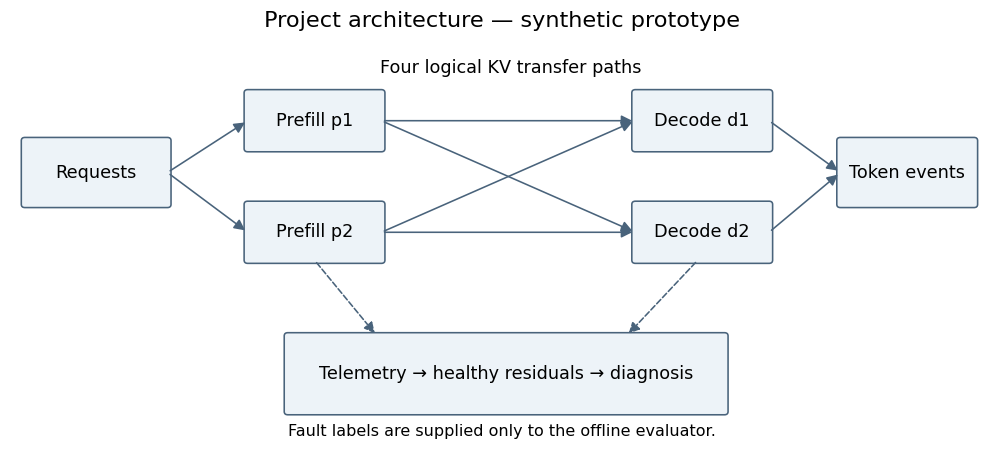

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.set(xlim=(0, 11), ylim=(0, 5)); ax.axis('off')
def node(x, y, w, h, text):
    ax.add_patch(FancyBboxPatch((x,y), w,h,boxstyle='round,pad=.04',facecolor='#edf3f8',edgecolor='#49637b'))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=11)
def edge(a,b,dashed=False):
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=14,
                                color='#49637b',linestyle='--' if dashed else '-'))
node(.15,2.9,1.6,.8,'Requests')
node(2.65,3.6,1.5,.7,'Prefill p1');node(2.65,2.2,1.5,.7,'Prefill p2')
node(7.0,3.6,1.5,.7,'Decode d1');node(7.0,2.2,1.5,.7,'Decode d2')
node(9.3,2.9,1.5,.8,'Token events')
for py in [3.95,2.55]:
    edge((1.75,3.3),(2.65,py))
    for dy in [3.95,2.55]:edge((4.15,py),(7,dy))
for dy in [3.95,2.55]:edge((8.5,dy),(9.3,3.3))
ax.text(5.6,4.55,'Four logical KV transfer paths',ha='center',fontsize=11)
node(3.1,.3,4.9,.95,'Telemetry → healthy residuals → diagnosis')
edge((3.4,2.2),(4.1,1.25),True);edge((7.7,2.2),(6.9,1.25),True)
ax.text(5.5,.0,'Fault labels are supplied only to the offline evaluator.',ha='center',fontsize=10)
plt.title('Project architecture — synthetic prototype',fontsize=14)
plt.show()

## 2 Telemetry inputs

The detector uses three tables. Fault labels are kept separately for evaluation.

| Table | Contents |
|---|---|
| `arrivals` | Request arrival, prompt length, configured output limit and route |
| `observations` | Stage, component, local duration and work features |
| `slo_events` | Client TTFT and token-gap measurements |

Times use seconds, durations use milliseconds, and KV size uses bytes. Missing work features cause abstention. Service durations exclude queueing; progression measurements need a separate baseline.

The simulator assumes immediate delivery, so `event_s` represents both completion and availability. Delayed collection requires separate timestamps and an updated validator and window selector. Use request-correlated records; aggregate histograms cannot reconstruct them.


In [4]:
OBS_COLUMNS = ['run_id','obs_id','request_id','stage','component','start_s',
               'event_s','duration_ms','prompt_tokens','uncached_tokens',
               'kv_bytes','context_tokens','batch_size','generated_so_far',
               'config_id','measurement_kind']
ARR_COLUMNS = ['run_id','request_id','arrival_s','prompt_tokens','max_new_tokens',
               'prefill_id','decode_id','path_id','config_id']
SLO_COLUMNS = ['run_id','request_id','event_s','metric','value_ms']
FORBIDDEN = {'fault','fault_component','true_component','slowdown','scenario',
             'kind','onset_s','end_s','eventual_output_length','final_output_tokens'}

def validate_tables(observations, arrivals, slo_events):
    """Reject inconsistent canonical records; missing feature values cause abstention later."""
    for frame, columns, label in [(observations,OBS_COLUMNS,'observations'),
                                   (arrivals,ARR_COLUMNS,'arrivals'),
                                   (slo_events,SLO_COLUMNS,'slo_events')]:
        missing = set(columns) - set(frame.columns)
        if missing: raise ValueError(f'{label}: missing columns {sorted(missing)}')
        if FORBIDDEN & set(frame.columns):
            raise ValueError(f'{label}: evaluation-only columns are prohibited')
        for name in ('run_id','request_id'):
            if frame[name].isna().any(): raise ValueError(f'{label}: null {name}')
    if observations.duplicated(['run_id','obs_id']).any():
        raise ValueError('Duplicate observation IDs')
    if arrivals.duplicated(['run_id','request_id']).any():
        raise ValueError('Duplicate request IDs')
    for frame in (observations,arrivals):
        if frame.config_id.isna().any():raise ValueError('Null configuration ID')
    for frame, cols in [(observations,['start_s','event_s','duration_ms']),
                         (arrivals,['arrival_s','prompt_tokens','max_new_tokens']),
                         (slo_events,['event_s','value_ms'])]:
        for c in cols:
            if not pd.api.types.is_numeric_dtype(frame[c]) or not np.isfinite(frame[c]).all():
                raise ValueError(f'{c} must be finite numeric data')
            if (frame[c] < 0).any(): raise ValueError(f'{c} must be nonnegative')
    if (observations.duration_ms <= 0).any(): raise ValueError('Nonpositive duration')
    if not np.allclose((observations.event_s-observations.start_s)*1000,
                       observations.duration_ms, rtol=1e-5, atol=1e-4):
        raise ValueError('Stage duration and local start/end timestamps disagree')
    if not observations.stage.isin(STAGES).all(): raise ValueError('Unknown stage')
    for s,g in observations.groupby('stage'):
        if not g.component.isin(COMPONENTS[s]).all(): raise ValueError('Unknown component ID')
        for c in FEATURES[s]:
            # Null features are allowed, but never silently filled with zero.
            if not pd.api.types.is_numeric_dtype(g[c]): raise ValueError(f'Nonnumeric {c}')
            v=g[c].dropna()
            if not np.isfinite(v).all() or (v<0).any(): raise ValueError(f'Invalid {c}')
    count_columns=['prompt_tokens','uncached_tokens','kv_bytes','context_tokens','batch_size','generated_so_far']
    for frame,cols in [(observations,count_columns),(arrivals,['prompt_tokens','max_new_tokens'])]:
        for c in cols:
            if not pd.api.types.is_numeric_dtype(frame[c]):raise ValueError(f'Nonnumeric {c}')
            v=frame[c].dropna()
            if not np.isfinite(v).all() or (v<0).any() or not np.allclose(v,np.round(v)):
                raise ValueError(f'{c} must contain nonnegative integer counts')
    if (observations.batch_size.dropna()<1).any():raise ValueError('batch_size must be positive')
    if (arrivals[['prompt_tokens','max_new_tokens']]<1).any().any():raise ValueError('Invalid request token count')
    if (observations.uncached_tokens>observations.prompt_tokens).any():raise ValueError('Uncached tokens exceed prompt')
    if not observations.measurement_kind.isin(['service','progression']).all():
        raise ValueError('Unknown measurement kind')
    if not slo_events.metric.isin(['ttft_ms','itl_ms']).all(): raise ValueError('Unsupported SLO metric')
    if slo_events.loc[slo_events.metric.eq('ttft_ms')].duplicated(['run_id','request_id']).any():
        raise ValueError('TTFT must have one observation per request')
    if not arrivals.prefill_id.isin(COMPONENTS['prefill']).all(): raise ValueError('Invalid prefill route')
    if not arrivals.decode_id.isin(COMPONENTS['decode']).all(): raise ValueError('Invalid decode route')
    expected_path='l'+arrivals.prefill_id.str[-1]+arrivals.decode_id.str[-1]
    if not arrivals.path_id.eq(expected_path).all(): raise ValueError('Invalid path mapping')
    a=arrivals.set_index(['run_id','request_id'])
    for frame in (observations, slo_events):
        keys=pd.MultiIndex.from_frame(frame[['run_id','request_id']])
        if not keys.isin(a.index).all(): raise ValueError('Unjoinable request ID')
        av=a.reindex(keys).arrival_s.to_numpy()
        time_values=frame.start_s.to_numpy() if 'start_s' in frame else frame.event_s.to_numpy()
        if (time_values+1e-8 < av).any(): raise ValueError('Observation predates arrival')
    keys=pd.MultiIndex.from_frame(observations[['run_id','request_id']])
    route=a.reindex(keys)
    expected=np.select([observations.stage.eq('prefill'),observations.stage.eq('transfer')],
                       [route.prefill_id.to_numpy(),route.path_id.to_numpy()],
                       default=route.decode_id.to_numpy())
    if not observations.component.eq(expected).all(): raise ValueError('Stage disagrees with route')
    if not observations.config_id.eq(route.config_id.to_numpy()).all():
        raise ValueError('Configuration mismatch within request')
    prompt=observations.prompt_tokens.to_numpy(float)
    if not np.allclose(prompt[np.isfinite(prompt)],route.prompt_tokens.to_numpy()[np.isfinite(prompt)]):
        raise ValueError('Observed prompt length disagrees with arrival')
    return True

def stack(runs,key):
    return pd.concat([r[key] for r in runs],ignore_index=True)

def detector_view(run):
    """An explicit boundary: metadata and intervention manifests cannot cross it."""
    return {k:run[k].copy() for k in ('observations','arrivals','slo_events')}

### Simulated testbed

Prefill and transfer use FIFO queues; decode serves one token at a time. Service duration depends on workload and random noise. Client latency also includes queueing. Faults slow operations that start during the intervention.

Paired fault and control runs share request work, routes and noise. Only completed operations are observed, so severe stalls may delay diagnosis.

The simulator uses batch size one and outputs of 8–24 tokens. It does not model real GPU execution, continuous batching, shared-network contention or collection delay.


In [5]:
from collections import deque
import heapq


def simulate_run(run_id, seed, duration_s=180, regime='normal',
                 fault_component=None, fault_start_s=75., fault_end_s=145.,
                 slowdown=3., workload_shift_s=None, sparse=False,
                 missing_transfer=False):
    """Produce reproducible *synthetic* PD telemetry, never measurements of vLLM.

    Each worker/path is a FIFO server. Decode schedules one token at a time,
    re-enqueuing the request after each token, a simplified round-robin model.
    No continuous batching, GPU kernels, network topology, or real model is
    simulated. batch_size=1; 8–24 tokens bound the generated response lengths.
    Stage observations measure service only; TTFT/ITL also include queue waits.
    TTFT ends at the first decode token (a simplifying serving convention).

    All random work and service noise are pre-drawn before scheduling, making
    same-seed fault/control runs share underlying randomness. A fault applies
    to service starting within [fault_start_s, fault_end_s); an in-flight task
    retains its assigned service duration. event_s is local completion/receipt
    time. Only observations received by duration_s are returned; pending tasks
    are right-censored. No hidden fault labels enter observations or arrivals.
    """
    regimes = {'normal', 'long', 'burst', 'cache'}
    components = ('p1', 'p2', 'd1', 'd2', 'l11', 'l12', 'l21', 'l22')
    if regime not in regimes:
        raise ValueError(f'regime must be one of {sorted(regimes)}')
    if fault_component is not None and fault_component not in components:
        raise ValueError(f'Unknown fault component: {fault_component}')
    if duration_s <= 0 or slowdown < 1:
        raise ValueError('duration_s must be positive and slowdown must be >= 1')
    if fault_component is not None and fault_end_s <= fault_start_s:
        raise ValueError('fault_end_s must exceed fault_start_s')

    rng = np.random.default_rng(seed)
    # A common candidate process is thinned by the workload regime. The fault
    # never changes candidates, routes, request features, or random draws.
    candidate_rate = 7.5
    candidate_times = []
    t = 0.
    while True:
        t += rng.exponential(1. / candidate_rate)
        if t >= duration_s:
            break
        candidate_times.append(t)
    candidate_times = np.asarray(candidate_times, dtype=float)
    n_candidates = len(candidate_times)
    regime_active = (np.ones(n_candidates, dtype=bool) if workload_shift_s is None
                     else candidate_times >= workload_shift_s)
    arrival_rate = np.where(regime_active & (regime == 'burst'), 5.0, 2.6)
    keep = rng.random(n_candidates) < arrival_rate / candidate_rate
    arrival_times = candidate_times[keep]
    active = regime_active[keep]
    n = len(arrival_times)

    base_prompt = rng.lognormal(np.log(1024.), .85, n)
    prompt_multiplier = np.where(active & (regime == 'long'), 2.1, 1.)
    prompts = (np.round(np.clip(base_prompt * prompt_multiplier, 128., 8192.)
                        / 32.) * 32.).astype(int)
    cache_draw = rng.random(n)
    normal_hit = np.select([cache_draw < .55, cache_draw < .75,
                            cache_draw < .95], [0., .25, .75], default=.95)
    shifted_hit = np.select([cache_draw < .10, cache_draw < .25,
                             cache_draw < .65], [0., .50, .85], default=.95)
    hit_fraction = np.where(active & (regime == 'cache'), shifted_hit, normal_hit)
    uncached = np.maximum(1, np.round(prompts * (1. - hit_fraction))).astype(int)
    # Abstract byte volume for conditioning transfer time; not a model KV size.
    kv_bytes = prompts.astype(np.int64) * 8192
    response_lengths = rng.integers(8, 25, n)
    route_draw_p, route_draw_d = rng.random(n), rng.random(n)
    first_probability = .985 if sparse else .5
    p_idx = np.where(route_draw_p < first_probability, 1, 2)
    d_idx = np.where(route_draw_d < first_probability, 1, 2)
    p_ids = np.array([f'p{x}' for x in p_idx])
    d_ids = np.array([f'd{x}' for x in d_idx])
    path_ids = np.array([f'l{p}{d}' for p, d in zip(p_idx, d_idx)])
    prefill_noise = rng.lognormal(-.5 * .12**2, .12, n)
    transfer_noise = rng.lognormal(-.5 * .10**2, .10, n)
    decode_noise = rng.lognormal(-.5 * .09**2, .09, (n, 24))
    prefill_base_ms = (15. + .024 * uncached + .0015 * uncached**2 / 8192.) * prefill_noise
    transfer_base_ms = (3. + kv_bytes / 1_500_000.) * transfer_noise
    token_positions = np.arange(24)[None, :]
    decode_base_ms = (18. + .0028 * (prompts[:, None] + token_positions)) * decode_noise
    request_ids = np.array([f'{run_id}-r{i:05d}' for i in range(n)])
    arrivals = pd.DataFrame({
        'run_id': run_id, 'request_id': request_ids, 'arrival_s': arrival_times,
        'prompt_tokens': prompts, 'max_new_tokens': response_lengths,
        'prefill_id': p_ids, 'decode_id': d_ids, 'path_id': path_ids,
        'config_id': 'synthetic-v1',
    })

    queue = {component: deque() for component in components}
    busy = {component: False for component in components}
    events = []
    sequence = 0
    observations, slo_rows = [], []
    previous_token_end = {}
    completed_requests = set()

    def push_event(when, kind, payload):
        nonlocal sequence
        sequence += 1
        heapq.heappush(events, (float(when), sequence, kind, payload))

    def start_next(component, now):
        if busy[component] or not queue[component]:
            return
        i, stage, token = queue[component].popleft()
        busy[component] = True
        if stage == 'prefill':
            base_ms = prefill_base_ms[i]
        elif stage == 'transfer':
            base_ms = transfer_base_ms[i]
        else:
            base_ms = decode_base_ms[i, token]
        degraded = (component == fault_component and
                    fault_start_s <= now < fault_end_s)
        duration_ms = float(base_ms * (slowdown if degraded else 1.))
        push_event(now + duration_ms / 1000., 'completion',
                   (i, stage, token, component, now, duration_ms))

    def enqueue(component, task, now):
        queue[component].append(task)
        start_next(component, now)

    for i, when in enumerate(arrival_times):
        push_event(when, 'arrival', i)

    while events:
        now, _, kind, payload = heapq.heappop(events)
        if now > duration_s:
            break
        if kind == 'arrival':
            i = payload
            enqueue(p_ids[i], (i, 'prefill', 0), now)
            continue
        i, stage, token, component, start, duration_ms = payload
        busy[component] = False
        if not (missing_transfer and stage == 'transfer'):
            obs_id = f'{request_ids[i]}-{stage}-{token}'
            observations.append({
                'run_id': run_id, 'obs_id': obs_id,
                'request_id': request_ids[i], 'stage': stage,
                'component': component, 'start_s': float(start),
                'event_s': float(now), 'duration_ms': duration_ms,
                'prompt_tokens': int(prompts[i]),
                'uncached_tokens': int(uncached[i]), 'kv_bytes': int(kv_bytes[i]),
                'context_tokens': int(prompts[i] + (token if stage == 'decode' else 0)),
                'batch_size': 1, 'generated_so_far': int(token),
                'config_id': 'synthetic-v1', 'measurement_kind': 'service',
            })
        if stage == 'prefill':
            enqueue(path_ids[i], (i, 'transfer', 0), now)
        elif stage == 'transfer':
            enqueue(d_ids[i], (i, 'decode', 0), now)
        else:
            metric = 'ttft_ms' if token == 0 else 'itl_ms'
            reference_time = arrival_times[i] if token == 0 else previous_token_end[i]
            slo_rows.append({'run_id': run_id, 'request_id': request_ids[i],
                             'event_s': float(now), 'metric': metric,
                             'value_ms': float((now - reference_time) * 1000.)})
            previous_token_end[i] = now
            if token + 1 < response_lengths[i]:
                enqueue(d_ids[i], (i, 'decode', token + 1), now)
            else:
                completed_requests.add(i)
        start_next(component, now)

    observation_columns = [
        'run_id', 'obs_id', 'request_id', 'stage', 'component', 'start_s',
        'event_s', 'duration_ms', 'prompt_tokens', 'uncached_tokens', 'kv_bytes',
        'context_tokens', 'batch_size', 'generated_so_far', 'config_id',
        'measurement_kind',
    ]
    obs = pd.DataFrame(observations, columns=observation_columns)
    if not obs.empty:
        obs = obs.sort_values(['event_s', 'obs_id']).reset_index(drop=True)
    slo_events = pd.DataFrame(slo_rows, columns=[
        'run_id', 'request_id', 'event_s', 'metric', 'value_ms'])
    if not slo_events.empty:
        slo_events = slo_events.sort_values('event_s', kind='stable').reset_index(drop=True)
    manifest_rows = []
    if fault_component is not None:
        manifest_rows.append({
            'run_id': run_id, 'episode_id': f'{run_id}-episode-1',
            'onset_s': float(fault_start_s), 'end_s': float(fault_end_s),
            'true_component': fault_component,
            'kind': 'mixed' if regime != 'normal' else 'degradation',
        })
    manifest = pd.DataFrame(manifest_rows, columns=[
        'run_id', 'episode_id', 'onset_s', 'end_s', 'true_component', 'kind'])
    return {
        'observations': obs, 'arrivals': arrivals, 'slo_events': slo_events,
        'manifest': manifest,
        'metadata': {
            'run_id': run_id, 'seed': int(seed), 'duration_s': float(duration_s),
            'regime': regime, 'workload_shift_s': workload_shift_s,
            'fault_component': fault_component, 'fault_start_s': fault_start_s,
            'fault_end_s': fault_end_s, 'slowdown': float(slowdown),
            'sparse': bool(sparse), 'missing_transfer': bool(missing_transfer),
            'n_arrivals': n, 'n_completed_requests': len(completed_requests),
            'n_right_censored_requests': n - len(completed_requests),
            'synthetic_only': True,
        },
    }

### Data partitions

Split healthy data by whole run:

- **Fit:** learn healthy duration models.
- **Scale:** normalize component scores.
- **Threshold:** calibrate alarm thresholds.

Healthy runs cover normal traffic, longer prompts, bursts and cache reuse. Final tests use separate runs. Models, thresholds and the normal-demand reference remain fixed during evaluation.


In [6]:
regimes=['normal','long','burst','cache']
fit_runs=[simulate_run(f'fit-{regime}',100+i,CFG.duration_s,regime=regime)
          for i,regime in enumerate(regimes)]
null_runs=[simulate_run(f'null-{regime}',200+i,CFG.duration_s,regime=regime)
           for i,regime in enumerate(regimes)]
threshold_runs=[simulate_run(f'threshold-{regime}',300+i,CFG.duration_s,regime=regime)
                for i,regime in enumerate(regimes)]
groups={'fit':fit_runs,'scale_calibration':null_runs,'threshold_calibration':threshold_runs}
for runs in groups.values():
    for run in runs:validate_tables(**detector_view(run))
display(pd.DataFrame([{'split':split,'run_id':r['metadata']['run_id'],
                      'requests':len(r['arrivals']),'stage_records':len(r['observations']),
                      'duration_s':r['metadata']['duration_s']}
                     for split,runs in groups.items() for r in runs]))
display(fit_runs[0]['observations'].head(6))

,split,run_id,requests,stage_records,duration_s
0,fit,fit-normal,498,8915,180.0
1,fit,fit-long,466,8387,180.0
2,fit,fit-burst,849,15119,180.0
3,fit,fit-cache,452,8271,180.0
4,scale_calibration,null-normal,472,8392,180.0
5,scale_calibration,null-long,460,8088,180.0
6,scale_calibration,null-burst,921,16290,180.0
7,scale_calibration,null-cache,454,8085,180.0
8,threshold_calibration,threshold-normal,455,8302,180.0
9,threshold_calibration,threshold-long,469,8327,180.0


,run_id,obs_id,request_id,stage,component,start_s,event_s,duration_ms,prompt_tokens,uncached_tokens,kv_bytes,context_tokens,batch_size,generated_so_far,config_id,measurement_kind
0,fit-normal,fit-normal-r00000-prefill-0,fit-normal-r00000,prefill,p1,0.301245,0.367840,66.594555,1792,1792,14680064,1792,1,0,synthetic-v1,service
1,fit-normal,fit-normal-r00000-transfer-0,fit-normal-r00000,transfer,l11,0.367840,0.387400,19.560232,1792,1792,14680064,1792,1,0,synthetic-v1,service
2,fit-normal,fit-normal-r00001-prefill-0,fit-normal-r00001,prefill,p1,0.382462,0.407512,25.050032,896,672,7340032,896,1,0,synthetic-v1,service
3,fit-normal,fit-normal-r00000-decode-0,fit-normal-r00000,decode,d1,0.387400,0.407742,20.341445,1792,1792,14680064,1792,1,0,synthetic-v1,service
4,fit-normal,fit-normal-r00001-transfer-0,fit-normal-r00001,transfer,l12,0.407512,0.415308,7.796220,896,672,7340032,896,1,0,synthetic-v1,service
5,fit-normal,fit-normal-r00000-decode-1,fit-normal-r00000,decode,d1,0.407742,0.433921,26.178823,1792,1792,14680064,1793,1,1,synthetic-v1,service


## 3 Healthy duration models

Fit median and p95 log-duration models for each stage using its work features. An operation receives a positive score when it exceeds the predicted healthy p95:

\[
e_o = \max\left(0,\frac{\log(t_o)-\widehat q_{0.95}(x_o)}{\max(\widehat q_{0.95}(x_o)-\widehat q_{0.50}(x_o),0.08)}\right).
\]

Here $t_o$ is duration and $x_o$ is the available work. Quantiles are kept ordered, and the denominator has a floor.

Unsupported features, configurations or measurement types produce no score. The range check covers individual features, not every possible combination. Scores are anomaly evidence, not failure probabilities.


In [7]:
class HealthyModels:
    def __init__(self, cfg=CFG):
        self.cfg=cfg; self.models={}; self.bounds={}; self.kinds={}
        self.historical={}; self.rate_reference={}; self.configs=set()

    @staticmethod
    def work_units(frame,stage):
        if stage=='prefill': return frame.uncached_tokens.to_numpy().clip(1)
        if stage=='transfer': return frame.kv_bytes.to_numpy().clip(1)
        return np.ones(len(frame))  # naive decode tokens/sec baseline

    def fit(self, observations):
        if observations.config_id.isna().any() or observations.config_id.nunique()!=1:
            raise ValueError('Fit one nonnull configuration per healthy baseline')
        self.configs=set(observations.config_id.unique())
        for stage in STAGES:
            g=observations.loc[observations.stage.eq(stage)].copy()
            g=g.dropna(subset=FEATURES[stage]+['duration_ms'])
            if len(g)<40: continue  # an absent model remains an explicit support gap
            self.kinds[stage]=set(g.measurement_kind.unique())
            if len(self.kinds[stage])!=1: raise ValueError('Do not mix timing semantics in one model')
            raw=g[FEATURES[stage]].to_numpy(float)
            lo=raw.min(axis=0);hi=raw.max(axis=0)
            pad=np.maximum((hi-lo)*0.15,np.maximum(1.,hi*0.05))
            pad=np.where(hi==lo,1e-8,pad)  # never invent support for unseen batching
            self.bounds[stage]=(np.maximum(0,lo-pad),hi+pad)
            sample=g.sample(min(len(g),self.cfg.model_rows_per_stage),random_state=self.cfg.seed)
            X=np.log1p(sample[FEATURES[stage]].to_numpy(float)); y=np.log(sample.duration_ms.to_numpy())
            fitted=[]
            for alpha in (.5,.95):
                m=GradientBoostingRegressor(loss='quantile',alpha=alpha,
                     n_estimators=self.cfg.trees,max_depth=3,min_samples_leaf=20,
                     learning_rate=.06,random_state=self.cfg.seed)
                fitted.append(m.fit(X,y))
            self.models[stage]=fitted
            self.historical[stage]=np.quantile(np.log(g.duration_ms),[.5,.95])
            rates=np.log(g.duration_ms.to_numpy()/self.work_units(g,stage))
            self.rate_reference[stage]=np.quantile(rates,[.5,.95])
        return self

    def score(self, observations):
        out=observations.copy()
        out['supported']=False
        out['support_reason']='missing_stage_model'
        for col in ['q50_log','q95_log','conditioned','historical','work_rate','median_residual']:
            out[col]=np.nan
        for stage in STAGES:
            if stage not in self.models: continue
            idx=out.index[out.stage.eq(stage)]
            g=out.loc[idx]; raw=g[FEATURES[stage]].to_numpy(float)
            finite=np.isfinite(raw).all(axis=1)
            lower,upper=self.bounds[stage]
            in_range=((raw>=lower)&(raw<=upper)).all(axis=1)&finite
            same=g.config_id.isin(self.configs).to_numpy() & g.measurement_kind.isin(self.kinds[stage]).to_numpy()
            good=in_range&same
            out.loc[idx,'support_reason']=np.where(~same,'configuration_or_timing_change',
                            np.where(~finite,'missing_features',np.where(~in_range,'outside_healthy_support','ok')))
            out.loc[idx,'supported']=good
            if not good.any(): continue
            use=idx[good]; X=np.log1p(raw[good]); target=np.log(out.loc[use,'duration_ms'].to_numpy())
            q50,q95=[m.predict(X) for m in self.models[stage]]
            q95=np.maximum(q95,q50+self.cfg.scale_floor)
            scale=np.maximum(q95-q50,self.cfg.scale_floor)
            out.loc[use,'q50_log']=q50;out.loc[use,'q95_log']=q95
            out.loc[use,'conditioned']=np.maximum(0,(target-q95)/scale)
            out.loc[use,'median_residual']=target-q50
            for method,reference,ys in [
                ('historical',self.historical[stage],target),
                ('work_rate',self.rate_reference[stage],
                 np.log(out.loc[use,'duration_ms'].to_numpy()/self.work_units(out.loc[use],stage)))]:
                a,b=reference
                out.loc[use,method]=np.maximum(0,(ys-b)/max(b-a,self.cfg.scale_floor))
        return out

### Component scores and baselines

Average operation scores within each request, then across requests. This prevents long responses from dominating a component window.

| Method | Comparison |
|---|---|
| `conditioned` | Healthy p95 for the measured work |
| `historical` | Healthy stage p95 without work conditioning |
| `work_rate` | Duration per uncached token, transferred byte or decode token |
| `matched_peer` | Work-normalized residuals of eligible same-stage peers |

Matched peer shares the healthy median model and may miss a slowdown common to all peers. Raw SLO alerts measure client slowdown but cannot identify a component.


In [8]:
def window_ends(end_s,cfg=CFG):
    return np.arange(cfg.window_s,end_s+1e-9,cfg.cadence_s)

def window_statistics(scored,end_s,cfg=CFG,run_ids=None):
    """Only event_s in (t-window,t] is visible. One vote per request/component."""
    rows=[]
    for rid in (scored.run_id.unique() if run_ids is None else run_ids):
        rg=scored.loc[scored.run_id.eq(rid)]
        for t in window_ends(end_s,cfg):
            w=rg.loc[(rg.event_s>t-cfg.window_s)&(rg.event_s<=t)]
            pending=[]
            for stage in STAGES:
                for comp in COMPONENTS[stage]:
                    g=w.loc[w.component.eq(comp)]
                    good=g.loc[g.supported]
                    n=g.request_id.nunique(); ng=good.request_id.nunique()
                    frac=float(g.supported.mean()) if len(g) else 0.
                    valid=ng>=cfg.min_requests and frac>=cfg.min_support_fraction
                    agg=good.groupby('request_id')[['conditioned','historical','work_rate','median_residual']].mean()
                    record=dict(run_id=rid,t_s=t,stage=stage,component=comp,
                                n_requests=n,n_supported=ng,support_fraction=frac,eligible=valid)
                    for method in METHODS[:3]:record[method]=float(agg[method].mean()) if valid else np.nan
                    record['median_residual']=float(agg.median_residual.median()) if valid else np.nan
                    record['reason']='ok' if valid else ('no_records' if not len(g) else
                                  ('low_support' if ng<cfg.min_requests else 'unsupported_features'))
                    pending.append(record)
            # Matched-peer baseline: work-normalized median residual relative to peers.
            for record in pending:
                peers=[x['median_residual'] for x in pending if x['stage']==record['stage']
                       and x['component']!=record['component'] and x['eligible']]
                record['matched_peer']=max(0,record['median_residual']-float(np.median(peers))) \
                      if record['eligible'] and peers else np.nan
                rows.append(record)
    return pd.DataFrame(rows)

def demand_windows(arrivals,end_s,cfg=CFG):
    rows=[]
    for rid,g in arrivals.groupby('run_id',sort=False):
        for t in window_ends(end_s,cfg):
            w=g.loc[(g.arrival_s>t-cfg.window_s)&(g.arrival_s<=t)]
            rows.append(dict(run_id=rid,t_s=t,arrival_rate=len(w)/cfg.window_s,
                prompt_median=float(w.prompt_tokens.median()) if len(w) else np.nan,
                budget_median=float(w.max_new_tokens.median()) if len(w) else np.nan))
    return pd.DataFrame(rows)

def slo_windows(events,run_ids,end_s,cfg=CFG):
    rows=[]
    for rid in run_ids:
        g=events.loc[events.run_id.eq(rid)]
        for t in window_ends(end_s,cfg):
            w=g.loc[(g.event_s>t-cfg.window_s)&(g.event_s<=t)]
            record=dict(run_id=rid,t_s=t)
            vals=[];valids=[]
            for metric,limit,minimum in [('ttft_ms',cfg.ttft_slo_ms,cfg.min_slo_requests),
                                          ('itl_ms',cfg.itl_slo_ms,cfg.min_itl_gaps)]:
                x=w.loc[w.metric.eq(metric),'value_ms'];valid=len(x)>=minimum
                fraction=float((x>limit).mean()) if len(x) else np.nan
                record[metric+'_p99']=float(x.quantile(.99)) if len(x) else np.nan
                record[metric+'_violation_fraction']=fraction
                record[metric+'_n']=len(x)
                record[metric+'_valid']=valid
                valids.append(valid);vals.append(bool(valid and fraction>cfg.allowed_violation_fraction))
            record['slo_alarm']=any(vals)
            record['slo_valid']=any(vals) or all(valids)  # known breach despite another missing metric
            record['slo_complete']=all(valids)
            rows.append(record)
    return pd.DataFrame(rows)

### Calibration

Normalize component scores using healthy medians and upper spreads. Set each method's threshold from the 99th percentile of healthy window maxima, then apply the two-window persistence rule.

This empirical threshold does not guarantee an hourly false-alarm rate. Measure false episodes separately on healthy test runs.

Demand change uses deviations in arrival rate, median prompt length and configured output budget. A demand change does not suppress component-degradation evidence.


In [9]:
class WindowCalibrator:
    """Separate score-scale fitting from threshold selection on whole healthy runs."""
    def fit_scale(self,null_windows):
        self.reference={}
        for method in METHODS:
            for c in ALL_COMPONENTS:
                v=null_windows.loc[null_windows.component.eq(c),method].dropna().to_numpy()
                if len(v)<10: continue
                med,hi=np.quantile(v,[.5,.95])
                self.reference[(method,c)]=(med,max(hi-med,CFG.component_scale_floor))
        return self

    def transform(self,windows):
        parts=[]
        for method in METHODS:
            f=windows[['run_id','t_s','stage','component','eligible','n_requests',
                       'n_supported','support_fraction','reason']].copy()
            f['method']=method;f['score']=np.nan
            for c in ALL_COMPONENTS:
                if (method,c) not in self.reference:continue
                med,scale=self.reference[(method,c)]
                mask=f.component.eq(c)
                f.loc[mask,'score']=(windows.loc[mask,method]-med)/scale
            f['eligible']=f.eligible & np.isfinite(f.score)
            parts.append(f)
        return pd.concat(parts,ignore_index=True)

    def fit_thresholds(self,threshold_windows):
        normalized=self.transform(threshold_windows);self.thresholds={}
        for method,g in normalized.groupby('method'):
            # Component maximum calibrates the same multi-comparison statistic used online.
            maxima=g.loc[g.eligible].groupby(['run_id','t_s']).score.max().dropna()
            if len(maxima)<10:raise ValueError('Too few healthy threshold windows')
            self.thresholds[method]=max(0.0,float(maxima.quantile(CFG.threshold_quantile)))
        return self

class DemandReference:
    columns=['arrival_rate','prompt_median','budget_median']
    def fit(self,normal_fit,normal_threshold):
        X=normal_fit[self.columns].to_numpy(float)
        self.center=np.nanmedian(X,axis=0)
        # Positive floors prevent small fluctuations in discrete medians exploding.
        self.scale=np.maximum(np.nanquantile(np.abs(X-self.center),.95,axis=0),[.3,100,2])
        v=self.score(normal_threshold)
        self.threshold=max(2.,float(np.quantile(v[np.isfinite(v)],.99)))
        return self
    def score(self,frame):
        return np.max(np.abs(frame[self.columns].to_numpy(float)-self.center)/self.scale,axis=1)

In [10]:
started=time.perf_counter()
models=HealthyModels().fit(stack(fit_runs,'observations'))
null_scored=models.score(stack(null_runs,'observations'))
null_windows=window_statistics(null_scored,CFG.duration_s)
threshold_scored=models.score(stack(threshold_runs,'observations'))
threshold_windows=window_statistics(threshold_scored,CFG.duration_s)
calibrator=WindowCalibrator().fit_scale(null_windows).fit_thresholds(threshold_windows)
normal_fit_demand=demand_windows(fit_runs[0]['arrivals'],CFG.duration_s)
normal_threshold_demand=demand_windows(threshold_runs[0]['arrivals'],CFG.duration_s)
demand_reference=DemandReference().fit(normal_fit_demand,normal_threshold_demand)
fit_elapsed=time.perf_counter()-started
baseline_id=hashlib.sha256(json.dumps({'settings':asdict(CFG),
    'fit_runs':[r['metadata']['run_id'] for r in fit_runs],
    'thresholds':calibrator.thresholds},sort_keys=True).encode()).hexdigest()[:12]
print(f'Frozen baseline {baseline_id}; fitting and calibration took {fit_elapsed:.2f} s on this CPU.')
display(pd.Series(calibrator.thresholds,name='Frozen component-score threshold').to_frame())
healthy_coverage=(null_scored.assign(covered=lambda d:np.where(d.supported,np.log(d.duration_ms)<=d.q95_log,np.nan))
    .groupby('stage').agg(records=('obs_id','size'),feature_support=('supported','mean'),
                         supported_records=('supported','sum'),
                         observed_q95_coverage=('covered','mean')))
display(healthy_coverage)

Frozen baseline e751beac401a; fitting and calibration took 3.02 s on this CPU.


,Frozen component-score threshold
conditioned,2.862999
historical,2.067562
matched_peer,2.598696
work_rate,3.638145


,records,feature_support,supported_records,observed_q95_coverage
stage,,,,
decode,36245,1.0,36245,0.953897
prefill,2305,1.0,2305,0.971800
transfer,2305,1.0,2305,0.965293


## 4 Windowed diagnosis

The detector replays observations in time order, using only measurements available at each evaluation. It returns SLO status, an explanation, up to three ranked components and reasons for abstention.

| Evidence | Output |
|---|---|
| Persistent component anomaly | Degradation; mixed if demand change also persists |
| SLO breach, persistent demand change, full coverage and no component anomaly | Workload |
| Missing or unresolved evidence without a persistent candidate | Unknown |
| No SLO breach, no component anomaly and valid coverage | No diagnosis |

A valid breach in either latency metric can raise an SLO alarm; an all-clear requires both metrics. TTFT counts requests, while ITL counts token gaps. Partial telemetry may support one suspect but cannot establish whole-system health. Live collection remains future work.


In [11]:
def make_decisions(component_windows,demand,slo,calibrator,demand_reference):
    """Deterministic forward scan; no fault metadata, scenario names or future aggregates."""
    ds=demand.copy();ds['demand_score']=demand_reference.score(ds)
    ds['demand_changed']=ds.demand_score>demand_reference.threshold
    look=ds.merge(slo,on=['run_id','t_s']).set_index(['run_id','t_s'])
    outputs=[]
    for (method,rid),g in component_windows.groupby(['method','run_id'],sort=False):
        streak={c:0 for c in ALL_COMPONENTS};demand_streak=0
        for t,w in g.groupby('t_s',sort=True):
            ctx=look.loc[(rid,t)]
            changed=bool(ctx.demand_changed) if np.isfinite(ctx.demand_score) else False
            demand_streak=demand_streak+1 if changed else 0
            demand_persistent=demand_streak>=CFG.persistence
            eligible=w.loc[w.eligible]
            supported=set(eligible.component)
            for c in ALL_COMPONENTS:
                val=eligible.loc[eligible.component.eq(c),'score']
                suspicious=len(val)>0 and float(val.iloc[0])>calibrator.thresholds[method]
                streak[c]=streak[c]+1 if suspicious else 0
            candidates=eligible.loc[eligible.component.map(streak)>=CFG.persistence]
            candidates=candidates.sort_values(['score','component'],ascending=[False,True])
            ranking=candidates.component.head(3).tolist()
            instantaneous=bool((eligible.score>calibrator.thresholds[method]).any())
            full_coverage=len(supported)==len(ALL_COMPONENTS)
            slowdown=bool(ctx.slo_alarm) or instantaneous or bool(ranking)
            if ranking: explanation='mixed' if demand_persistent else 'degradation'
            elif not full_coverage or not bool(ctx.slo_valid):explanation='unknown'
            elif not slowdown:explanation=None
            elif demand_persistent and not instantaneous:explanation='workload'
            else:explanation='unknown'
            reason=''
            if explanation=='unknown':
                reason='insufficient_component_coverage' if not full_coverage else \
                       ('insufficient_slo_data' if not bool(ctx.slo_valid) else 'unresolved_slowdown')
            elif not full_coverage:reason='partial_coverage_supported_candidates_only'
            outputs.append(dict(run_id=rid,t_s=float(t),method=method,
                slo_alarm=bool(ctx.slo_alarm),slo_valid=bool(ctx.slo_valid),
                explanation=explanation,ranked_components=ranking,
                degradation=bool(ranking),demand_changed=demand_persistent,
                full_coverage=full_coverage,eligible_components=len(supported),
                unknown_reason=reason,max_score=float(eligible.score.max()) if len(eligible) else np.nan,
                threshold=calibrator.thresholds[method]))
    return pd.DataFrame(outputs)

def run_detector(view,models,calibrator,demand_reference,end_s=CFG.duration_s):
    validate_tables(**view)
    scored=models.score(view['observations'])
    windows=window_statistics(scored,end_s,run_ids=view['arrivals'].run_id.unique())
    comp=calibrator.transform(windows)
    demand=demand_windows(view['arrivals'],end_s)
    slo=slo_windows(view['slo_events'],view['arrivals'].run_id.unique(),end_s)
    decisions=make_decisions(comp,demand,slo,calibrator,demand_reference)
    return decisions,comp,slo

In [12]:
cal_decisions=[]
for run in threshold_runs:
    d,_,_=run_detector(detector_view(run),models,calibrator,demand_reference)
    cal_decisions.append(d)
cal_decisions=pd.concat(cal_decisions,ignore_index=True)
def alarm_episodes(series):
    x=np.asarray(series,dtype=bool)
    return int(np.sum(x & ~np.r_[False,x[:-1]])) if len(x) else 0
cal_audit=[]
for method,g in cal_decisions.groupby('method'):
    n_alarm=sum(alarm_episodes(r.sort_values('t_s').degradation) for _,r in g.groupby('run_id'))
    hours=len(threshold_runs)*(CFG.duration_s-CFG.window_s)/3600
    cal_audit.append({'method':method,'healthy_alarm_episodes':n_alarm,
                      'monitored_hours':hours,'episodes_per_hour':n_alarm/hours,
                      'full_coverage':g.full_coverage.mean()})
display(pd.DataFrame(cal_audit))
print('This is calibration exposure, not unbiased test performance. Zero alarms in a short run '
      'does not establish a production false-alarm guarantee.')

,method,healthy_alarm_episodes,monitored_hours,episodes_per_hour,full_coverage
0,conditioned,0,0.166667,0.0,1.0
1,historical,0,0.166667,0.0,1.0
2,matched_peer,0,0.166667,0.0,1.0
3,work_rate,0,0.166667,0.0,1.0


This is calibration exposure, not unbiased test performance. Zero alarms in a short run does not establish a production false-alarm guarantee.


## 5 Experiments

Test normal traffic, longer prompts, bursts, isolated worker/path faults, combined workload and degradation, sparse traffic, and missing transfer records. Each scenario has two independent repetitions.

Faults multiply the target's service time by three for operations starting between 75 and 145 simulated seconds. Fault labels are used only by the evaluator. Each injected run has a paired healthy control.


In [13]:
specs=[
    ('healthy',{}),
    ('workload_long',{'regime':'long','workload_shift_s':60.}),
    ('workload_burst',{'regime':'burst','workload_shift_s':60.}),
    ('prefill_fault',{'fault_component':'p1','slowdown':3.}),
    ('decode_fault',{'fault_component':'d1','slowdown':3.}),
    ('transfer_fault',{'fault_component':'l11','slowdown':3.}),
    ('mixed',{'regime':'long','workload_shift_s':50.,'fault_component':'d1','slowdown':3.}),
    ('sparse_fault',{'sparse':True,'fault_component':'p2','slowdown':3.}),
    ('missing_transfer',{'missing_transfer':True,'fault_component':'l11','slowdown':3.}),
]
test_runs=[];controls={};case_lookup={}
for rep in range(2):
    for i,(case,kwargs) in enumerate(specs):
        seed=1000+100*rep+i;rid=f'test-{case}-{rep}'
        run=simulate_run(rid,seed,CFG.duration_s,**kwargs)
        test_runs.append(run);case_lookup[rid]={'case':case,'replicate':rep}
        if kwargs.get('fault_component'):
            clean={k:v for k,v in kwargs.items() if k!='fault_component'}
            controls[rid]=simulate_run(rid+'-control',seed,CFG.duration_s,**clean)
print(f'{len(test_runs)} independent test runs; {len(controls)} paired healthy controls.')
print('Faults last from 75 s to 145 s. Paired controls share underlying random work and service noise.')

18 independent test runs; 12 paired healthy controls.
Faults last from 75 s to 145 s. Paired controls share underlying random work and service noise.


In [14]:
all_decisions=[];all_components=[];all_slos=[];run_timings=[]
for run in test_runs:
    started=time.perf_counter()
    d,c,s=run_detector(detector_view(run),models,calibrator,demand_reference)
    elapsed=time.perf_counter()-started
    rid=run['metadata']['run_id']
    all_decisions.append(d);all_components.append(c);all_slos.append(s)
    run_timings.append({'run_id':rid,'records':len(run['observations']),
                        'offline_analysis_seconds':elapsed})
decisions=pd.concat(all_decisions,ignore_index=True)
component_scores=pd.concat(all_components,ignore_index=True)
slo_results=pd.concat(all_slos,ignore_index=True)
run_timings=pd.DataFrame(run_timings)
print('Completed evaluation with the frozen models and thresholds.')
display(decisions.loc[decisions.method.eq('conditioned'),
                     ['run_id','t_s','slo_alarm','explanation','ranked_components','unknown_reason']].tail(8))

Completed evaluation with the frozen models and thresholds.


,run_id,t_s,slo_alarm,explanation,ranked_components,unknown_reason
1096,test-missing_transfer-1,110.0,True,unknown,[],insufficient_component_coverage
1097,test-missing_transfer-1,120.0,True,unknown,[],insufficient_component_coverage
1098,test-missing_transfer-1,130.0,False,unknown,[],insufficient_component_coverage
1099,test-missing_transfer-1,140.0,False,unknown,[],insufficient_component_coverage
1100,test-missing_transfer-1,150.0,True,unknown,[],insufficient_component_coverage
1101,test-missing_transfer-1,160.0,True,unknown,[],insufficient_component_coverage
1102,test-missing_transfer-1,170.0,True,unknown,[],insufficient_component_coverage
1103,test-missing_transfer-1,180.0,True,unknown,[],insufficient_component_coverage


### Incident results

Keep every injected incident in the denominator, including unresolved cases. Evaluate from fault onset until one window after the fault ends, capped by the run horizon.

- **Diagnosis occurrence:** any ranking in this interval, including an incorrect or already-active one.
- **First top 1 / top 3:** whether the first ranking identifies the injected target.
- **New diagnostic delay:** time from onset to a new diagnostic episode; undefined when no new episode occurs.

SLO relevance means a breach occurred during the fault. Compare paired controls before attributing that breach to the fault. Pre-existing SLO alarms are not counted as newly triggered by a later injection.


In [15]:
def evaluate_incidents(runs,decisions,slo_results,controls):
    rows=[]
    for run in runs:
        for episode in run['manifest'].to_dict('records'):
            rid=episode['run_id'];onset=episode['onset_s'];stop=episode['end_s']
            # Fixed eligibility, independent of diagnostics and their support/thresholds.
            s=slo_results.loc[slo_results.run_id.eq(rid)]
            during=s.loc[s.t_s.between(onset,stop)]
            eligible=bool(during.slo_alarm.any())
            before=s.loc[s.t_s<onset].sort_values('t_s')
            already=bool(before.slo_alarm.iloc[-1]) if len(before) else False
            new_slo=during.loc[during.slo_alarm,'t_s']
            control=controls[rid]
            cs=slo_windows(control['slo_events'],[control['metadata']['run_id']],CFG.duration_s)
            control_breach=bool(cs.loc[cs.t_s.between(onset,stop),'slo_alarm'].any())
            for method in METHODS:
                full=decisions.loc[decisions.run_id.eq(rid)&decisions.method.eq(method)].sort_values('t_s').copy()
                full['new_diagnostic_alarm']=full.degradation & ~full.degradation.shift(1,fill_value=False)
                prior=full.loc[full.t_s<onset]
                diagnostic_already=bool(prior.degradation.iloc[-1]) if len(prior) else False
                d=full.loc[full.t_s.between(onset,min(stop+CFG.window_s,CFG.duration_s))]
                diagnosed=d.loc[d.degradation].sort_values('t_s')
                new_diagnosed=d.loc[d.new_diagnostic_alarm]
                emitted=bool(len(diagnosed))
                first_rank=diagnosed.ranked_components.iloc[0] if emitted else []
                correct=d.loc[d.ranked_components.apply(lambda x:episode['true_component'] in x)]
                rows.append({**episode,'method':method,'slo_relevant':eligible,
                    'paired_control_slo_breach':control_breach,'slo_already_active':already,
                    'diagnostic_alarm_already_active':diagnostic_already,'new_diagnosis':bool(len(new_diagnosed)),
                    'new_slo_delay_s':float(new_slo.iloc[0]-onset) if len(new_slo) and not already else np.nan,
                    'diagnosed':emitted,'diagnosis_delay_s':float(new_diagnosed.t_s.iloc[0]-onset) if len(new_diagnosed) else np.nan,
                    'first_top1_hit':bool(first_rank and first_rank[0]==episode['true_component']),
                    'first_top3_hit':episode['true_component'] in first_rank,
                    'ever_top3_hit':bool(len(correct)),
                    'correct_diagnosis_delay_s':float(correct.t_s.min()-onset) if len(correct) else np.nan,
                    'first_explanation':diagnosed.explanation.iloc[0] if emitted else 'unknown',
                    'any_full_coverage':bool(d.full_coverage.any())})
    return pd.DataFrame(rows)

incidents=evaluate_incidents(test_runs,decisions,slo_results,controls)
summary=[]
for method,g in incidents.groupby('method'):
    eligible=g.loc[g.slo_relevant];emitted=g.loc[g.diagnosed]
    summary.append({'method':method,'all_injected_incidents':len(g),
      'diagnosis_recall_all':g.diagnosed.mean(),
      'new_diagnosis_fraction':g.new_diagnosis.mean(),
      'slo_relevant_incidents':len(eligible),
      'diagnosis_recall_slo_relevant':eligible.diagnosed.mean() if len(eligible) else np.nan,
      'first_top1_all':g.first_top1_hit.mean(),'first_top3_all':g.first_top3_hit.mean(),
      'first_top1_given_diagnosis':emitted.first_top1_hit.mean() if len(emitted) else np.nan,
      'median_diagnosis_delay_s':emitted.diagnosis_delay_s.median() if len(emitted) else np.nan,
      'missed_incidents':int((~g.diagnosed).sum())})
summary=pd.DataFrame(summary).set_index('method')
display(summary.round(3))
display(incidents.loc[incidents.method.eq('conditioned'),
     ['run_id','true_component','slo_relevant','paired_control_slo_breach','slo_already_active',
      'diagnosed','first_top1_hit','diagnosis_delay_s','first_explanation']])
print('Raw SLO alerting is shared across methods and is a detection-only baseline: '
      'it has no component localization score. Sub-SLO injected faults remain in the all-incident denominator.')

,all_injected_incidents,diagnosis_recall_all,new_diagnosis_fraction,slo_relevant_incidents,diagnosis_recall_slo_relevant,first_top1_all,first_top3_all,first_top1_given_diagnosis,median_diagnosis_delay_s,missed_incidents
method,,,,,,,,,,
conditioned,12,0.667,0.667,12,0.667,0.667,0.667,1.000,15.0,4
historical,12,0.583,0.583,12,0.583,0.583,0.583,1.000,15.0,5
matched_peer,12,0.667,0.667,12,0.667,0.583,0.583,0.875,30.0,4
work_rate,12,0.500,0.500,12,0.500,0.500,0.500,1.000,15.0,6


,run_id,true_component,slo_relevant,paired_control_slo_breach,slo_already_active,diagnosed,first_top1_hit,diagnosis_delay_s,first_explanation
0,test-prefill_fault-0,p1,True,True,False,True,True,15.0,degradation
4,test-decode_fault-0,d1,True,True,True,True,True,15.0,degradation
8,test-transfer_fault-0,l11,True,True,True,True,True,15.0,degradation
12,test-mixed-0,d1,True,True,True,True,True,15.0,mixed
16,test-sparse_fault-0,p2,True,True,True,False,False,NaN,unknown
20,test-missing_transfer-0,l11,True,True,True,False,False,NaN,unknown
24,test-prefill_fault-1,p1,True,True,True,True,True,15.0,degradation
28,test-decode_fault-1,d1,True,True,True,True,True,15.0,degradation
32,test-transfer_fault-1,l11,True,True,True,True,True,15.0,degradation
36,test-mixed-1,d1,True,True,True,True,True,15.0,mixed


Raw SLO alerting is shared across methods and is a detection-only baseline: it has no component localization score. Sub-SLO injected faults remain in the all-incident denominator.


### False alarms and explanations

Healthy tests include workload changes. Count component accusations as false diagnoses; an SLO breach alone is not a false component diagnosis. Report episodes per simulated cluster-hour and the fraction of accusatory windows.

Score explanations in stable, SLO-alarming intervention windows. Keep unknown outputs in the denominator. Overlapping windows are correlated, and intervention labels do not establish an exclusive physical cause.


In [16]:
healthy_ids=[r['metadata']['run_id'] for r in test_runs if r['manifest'].empty]
healthy_table=[]
for method in METHODS:
    g=decisions.loc[decisions.method.eq(method)&decisions.run_id.isin(healthy_ids)]
    evaluated=g.loc[g.eligible_components>0]
    count=sum(alarm_episodes(r.sort_values('t_s').degradation) for _,r in g.groupby('run_id'))
    hours=len(healthy_ids)*(CFG.duration_s-CFG.window_s)/3600.
    healthy_table.append({'method':method,'healthy_monitored_hours':hours,
       'false_component_alarm_episodes':count,'episodes_per_cluster_hour':count/hours,
       'cluster_windows_with_false_accusation':evaluated.degradation.mean(),
       'full_component_coverage':g.full_coverage.mean(),
       'valid_slo_alarm_window_fraction':g.slo_alarm.mean()})
healthy_table=pd.DataFrame(healthy_table).set_index('method')
display(healthy_table.round(3))
# Explanation evaluation is restricted to defined stable episode interiors.
# Workload labels represent experimental interventions, not proven exclusive causes.
explanation_rows=[]
for run in test_runs:
    meta=run['metadata'];rid=meta['run_id'];case=case_lookup[rid]['case']
    if case=='healthy':continue
    if not run['manifest'].empty:
        onset=float(run['manifest'].onset_s.iloc[0]);end=float(run['manifest'].end_s.iloc[0])
        truth=str(run['manifest'].kind.iloc[0])
    else:
        onset=float(meta['workload_shift_s']);end=CFG.duration_s;truth='workload'
    w=decisions.loc[decisions.run_id.eq(rid)&decisions.t_s.between(onset+CFG.window_s,end)]
    eligible_slo=slo_results.loc[slo_results.run_id.eq(rid)&slo_results.slo_alarm,'t_s']
    w=w.loc[w.t_s.isin(eligible_slo)]  # independent observed slowdown criterion
    for row in w.to_dict('records'):
        explanation_rows.append({'run_id':rid,'method':row['method'],'truth':truth,
             'predicted':row['explanation'] or 'no_diagnosis','t_s':row['t_s']})
explanation_eval=pd.DataFrame(explanation_rows)
display(explanation_eval.groupby('method').apply(
    lambda g:pd.Series({'slowdown_windows':len(g),
        'explanation_accuracy':(g.truth==g.predicted).mean(),
        'unknown_fraction':g.predicted.eq('unknown').mean(),
        'explanation_coverage':(~g.predicted.isin(['unknown','no_diagnosis'])).mean()}),
    include_groups=False).round(3))
print('Window fractions are descriptive; overlapping windows are not independent trials.')

,healthy_monitored_hours,false_component_alarm_episodes,episodes_per_cluster_hour,cluster_windows_with_false_accusation,full_component_coverage,valid_slo_alarm_window_fraction
method,,,,,,
conditioned,0.25,1,4.0,0.021,1.0,0.854
historical,0.25,0,0.0,0.000,1.0,0.854
work_rate,0.25,0,0.0,0.000,1.0,0.854
matched_peer,0.25,0,0.0,0.000,1.0,0.854


,slowdown_windows,explanation_accuracy,unknown_fraction,explanation_coverage
method,,,,
conditioned,83.0,0.771,0.193,0.807
historical,83.0,0.699,0.289,0.711
matched_peer,83.0,0.795,0.193,0.807
work_rate,83.0,0.699,0.289,0.711


Window fractions are descriptive; overlapping windows are not independent trials.


### Result plots

The shaded interval marks the decode fault. Compare component scores with the latency trace, then read the incident and explanation charts together with false-alarm results.

Localization, false alarms and unknown outcomes describe different trade-offs. This small synthetic experiment does not establish general superiority.


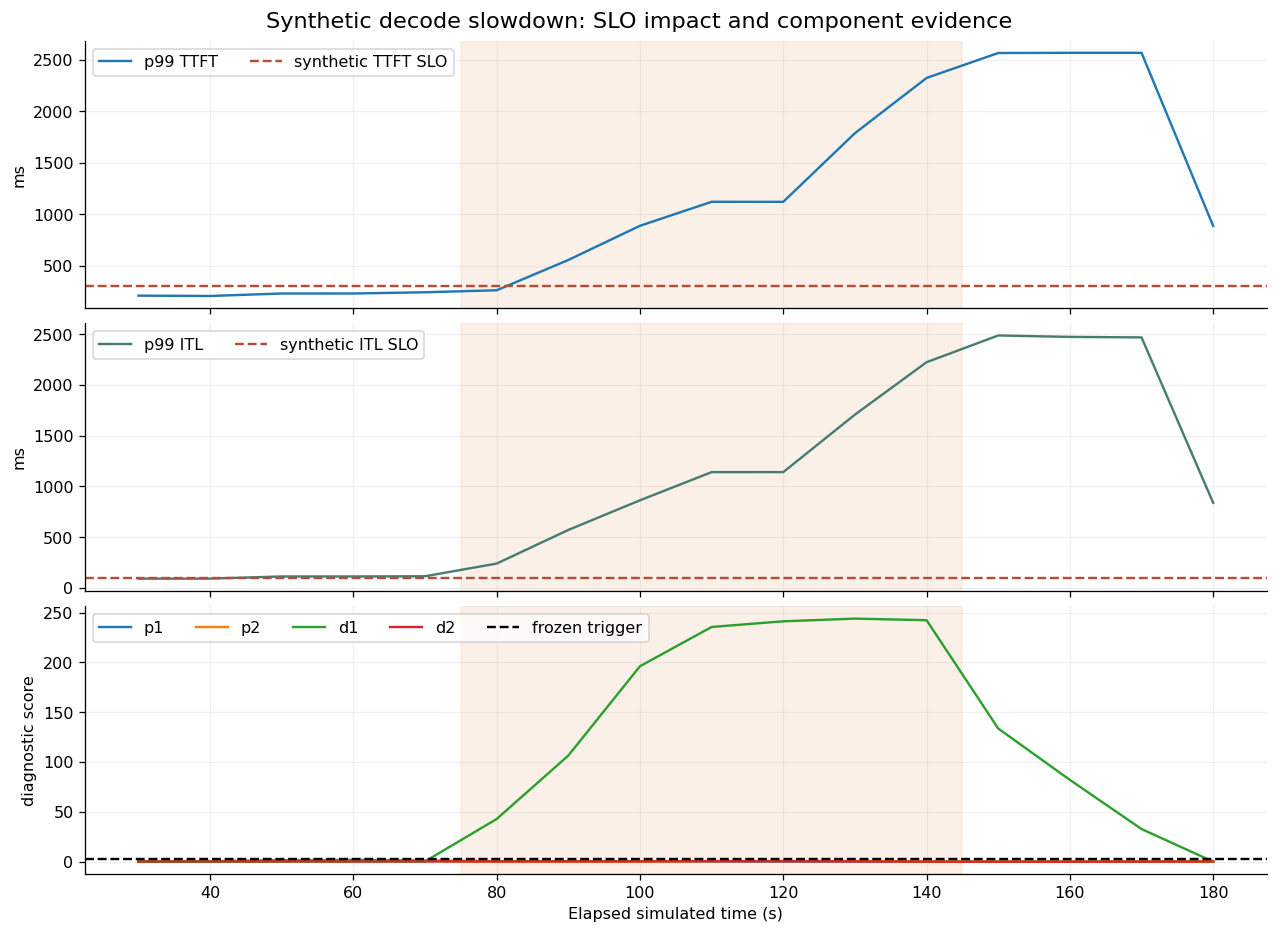

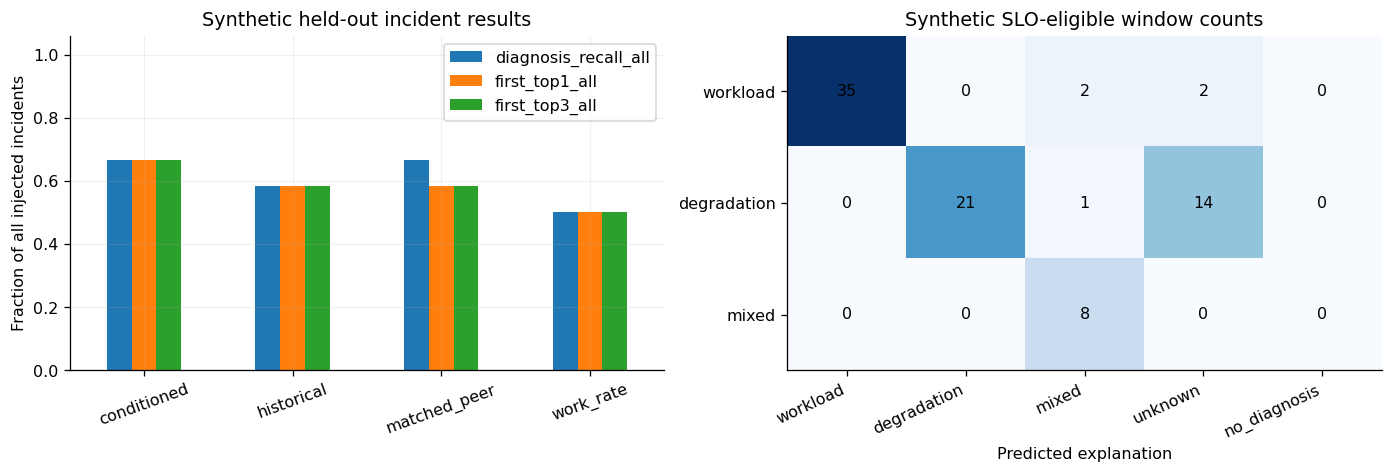

In [17]:
chosen='test-decode_fault-0'
run=next(r for r in test_runs if r['metadata']['run_id']==chosen)
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True,layout='constrained')
sw=slo_results.loc[slo_results.run_id.eq(chosen)]
axes[0].plot(sw.t_s,sw.ttft_ms_p99,label='p99 TTFT')
axes[0].axhline(CFG.ttft_slo_ms,color='#b54c35',ls='--',label='synthetic TTFT SLO')
axes[0].set_ylabel('ms');axes[0].legend(loc='upper left',ncol=2)
axes[1].plot(sw.t_s,sw.itl_ms_p99,color='#477d71',label='p99 ITL')
axes[1].axhline(CFG.itl_slo_ms,color='#b54c35',ls='--',label='synthetic ITL SLO')
axes[1].set_ylabel('ms');axes[1].legend(loc='upper left',ncol=2)
cc=component_scores.loc[component_scores.run_id.eq(chosen)&component_scores.method.eq('conditioned')]
for c in ['p1','p2','d1','d2']:
    g=cc.loc[cc.component.eq(c)];axes[2].plot(g.t_s,g.score,label=c)
axes[2].axhline(calibrator.thresholds['conditioned'],color='black',ls='--',label='frozen trigger')
axes[2].set_ylabel('diagnostic score');axes[2].set_xlabel('Elapsed simulated time (s)')
axes[2].legend(ncol=5,loc='upper left')
for ax in axes:ax.axvspan(75,145,color='#edc7a4',alpha=.25)
fig.suptitle('Synthetic decode slowdown: SLO impact and component evidence',fontsize=14)
plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
summary[['diagnosis_recall_all','first_top1_all','first_top3_all']].plot.bar(ax=axes[0],rot=20)
axes[0].set_ylim(0,1.06);axes[0].set_ylabel('Fraction of all injected incidents')
axes[0].set_title('Synthetic held-out incident results');axes[0].set_xlabel('')
conf=pd.crosstab(explanation_eval.loc[explanation_eval.method.eq('conditioned'),'truth'],
                 explanation_eval.loc[explanation_eval.method.eq('conditioned'),'predicted'])
conf=conf.reindex(index=['workload','degradation','mixed'],
                  columns=['workload','degradation','mixed','unknown','no_diagnosis'],fill_value=0)
im=axes[1].imshow(conf,aspect='auto',cmap='Blues')
axes[1].grid(False);axes[1].set_xticks(range(len(conf.columns)),conf.columns,rotation=25,ha='right')
axes[1].set_yticks(range(len(conf.index)),conf.index);axes[1].set_xlabel('Predicted explanation')
axes[1].set_title('Synthetic SLO-eligible window counts')
for i in range(len(conf.index)):
    for j in range(len(conf.columns)):axes[1].text(j,i,str(conf.iloc[i,j]),ha='center',va='center')
plt.show()

## 6 Validation

Check data separation, exclusion of fault labels, consistency under time-ordered replay, input validation and missing-data behaviour. Confirm that SLO alerts remain independent, unresolved incidents stay in recall, and pre-existing alarms are handled correctly.


In [18]:
checks=[]
def checked(name,fn):
    fn();checks.append({'check':name,'result':'PASS'})
def must_raise(fn):
    try:fn()
    except ValueError:return
    raise AssertionError('Expected a validation failure')

def check_splits():
    partitions=list(groups.values())+[test_runs]
    ids=[set(stack(rs,'arrivals').run_id) for rs in partitions]
    for i in range(len(ids)):
        for j in range(i):assert ids[i].isdisjoint(ids[j])
checked('Whole-run split isolation',check_splits)

probe=next(r for r in test_runs if r['metadata']['run_id']=='test-decode_fault-0')
base=decisions.loc[decisions.run_id.eq(probe['metadata']['run_id'])].reset_index(drop=True)
def check_truth():
    changed=copy.deepcopy(probe)
    changed['manifest']['true_component']='p2';changed['metadata']['fault_component']='p2'
    got,_,_=run_detector(detector_view(changed),models,calibrator,demand_reference)
    pd.testing.assert_frame_equal(base,got.reset_index(drop=True))
checked('Changing ground truth does not change detection',check_truth)

def check_future():
    view=detector_view(probe);cut=90.
    view['observations']=view['observations'].loc[view['observations'].event_s<=cut].copy()
    view['slo_events']=view['slo_events'].loc[view['slo_events'].event_s<=cut].copy()
    view['arrivals']=view['arrivals'].loc[view['arrivals'].arrival_s<=cut].copy()
    prefix,_,_=run_detector(view,models,calibrator,demand_reference,end_s=cut)
    want=base.loc[base.t_s<=cut].reset_index(drop=True)
    pd.testing.assert_frame_equal(want,prefix.reset_index(drop=True))
checked('Prefix invariance and observation availability',check_future)

def check_bad_duration():
    v=detector_view(probe);v['observations'].loc[0,'duration_ms']=-1
    must_raise(lambda:validate_tables(**v))
checked('Negative durations rejected',check_bad_duration)
def check_duplicate():
    v=detector_view(probe);v['arrivals']=pd.concat([v['arrivals'],v['arrivals'].iloc[[0]]])
    must_raise(lambda:validate_tables(**v))
checked('Duplicate request IDs rejected',check_duplicate)
def check_label_column():
    v=detector_view(probe);v['observations']['true_component']='d1'
    must_raise(lambda:validate_tables(**v))
checked('Evaluation labels rejected at detector boundary',check_label_column)

def check_missing():
    v=detector_view(test_runs[0]);v['observations']=v['observations'].iloc[:0].copy()
    d,_,_=run_detector(v,models,calibrator,demand_reference)
    assert d.explanation.eq('unknown').all() and not d.degradation.any()
checked('Empty telemetry yields unknown, not healthy',check_missing)

def check_unseen_config():
    v=detector_view(test_runs[0]);v['observations']['config_id']='unseen';v['arrivals']['config_id']='unseen'
    d,_,_=run_detector(v,models,calibrator,demand_reference)
    assert d.explanation.eq('unknown').all() and not d.degradation.any()
checked('Configuration changes invalidate healthy baseline',check_unseen_config)

def check_missing_model():
    small=copy.deepcopy(models);small.models.pop('transfer')
    s=small.score(test_runs[0]['observations'])
    assert not s.loc[s.stage.eq('transfer'),'supported'].any()
    assert s.loc[s.stage.eq('prefill'),'supported'].any()
checked('Missing stage model abstains without disabling other stages',check_missing_model)

def check_slo_independence():
    assert decisions.groupby(['run_id','t_s']).slo_alarm.nunique().max()==1
checked('SLO alarm is independent of diagnostic baseline',check_slo_independence)

def check_denominator():
    expected=sum(len(r['manifest']) for r in test_runs)
    assert incidents.groupby('method').size().eq(expected).all()
    blank=decisions.copy();blank['degradation']=False
    blank['ranked_components']=[[] for _ in range(len(blank))]
    blank['explanation']='unknown'
    failed=evaluate_incidents(test_runs,blank,slo_results,controls)
    assert len(failed)==expected*len(METHODS) and not failed.diagnosed.any()
checked('Missed incidents remain in recall denominator',check_denominator)

def check_already_active():
    # Controlled metric fixture verifies this edge case independently of simulation outcomes.
    ss=slo_results.copy();rid=probe['metadata']['run_id']
    ss.loc[ss.run_id.eq(rid)&ss.t_s.eq(70.),'slo_alarm']=True
    inc=evaluate_incidents([probe],decisions,ss,controls)
    assert inc.slo_already_active.all() and inc.new_slo_delay_s.isna().all()
checked('An existing SLO alarm is not credited to a later fault',check_already_active)
display(pd.DataFrame(checks))

,check,result
0,Whole-run split isolation,PASS
1,Changing ground truth does not change detection,PASS
2,Prefix invariance and observation availability,PASS
3,Negative durations rejected,PASS
4,Duplicate request IDs rejected,PASS
5,Evaluation labels rejected at detector boundary,PASS
6,"Empty telemetry yields unknown, not healthy",PASS
7,Configuration changes invalidate healthy baseline,PASS
8,Missing stage model abstains without disabling other stages,PASS
9,SLO alarm is independent of diagnostic baseline,PASS


## 7 Real telemetry

`load_telemetry_csv(directory)` reads `observations.csv`, `arrivals.csv` and `slo_events.csv` using the schema above.

Before real experiments:

1. Pin the model, serving stack, connector and worker placement.
2. Verify request IDs, routes, stage boundaries and local timing. Avoid subtracting unsynchronized host clocks or independent percentiles.
3. Separate completion from collector availability and handle delayed or dropped records.
4. Fit new models and thresholds on independent real healthy runs.
5. Run paired fault/control experiments and measure observer overhead.

Deduplicate token events in the collector; the current schema cannot identify duplicate ITL deliveries. A stream chunk may contain several tokens, so chunk gaps must be labelled separately. Aggregate metrics and final-response timing alone may not support path attribution.

Optional `export_results()` saves synthetic result tables and empty input templates locally. It is disabled by default.


In [19]:
def load_telemetry_csv(directory):
    """Import canonical CSVs, not marginal Prometheus histograms."""
    root=Path(directory)
    files={'observations':('observations.csv',OBS_COLUMNS),
           'arrivals':('arrivals.csv',ARR_COLUMNS),
           'slo_events':('slo_events.csv',SLO_COLUMNS)}
    result={}
    for key,(filename,required) in files.items():
        data=pd.read_csv(root/filename,dtype=str)  # preserve leading zeros in identifiers
        if FORBIDDEN&set(data.columns):raise ValueError(f'{filename}: contains evaluation labels')
        missing=set(required)-set(data.columns)
        if missing:raise ValueError(f'{filename}: missing {sorted(missing)}')
        numeric={'observations':['start_s','event_s','duration_ms','prompt_tokens','uncached_tokens',
                  'kv_bytes','context_tokens','batch_size','generated_so_far'],
                 'arrivals':['arrival_s','prompt_tokens','max_new_tokens'],
                 'slo_events':['event_s','value_ms']}[key]
        for col in numeric:data[col]=pd.to_numeric(data[col],errors='raise')
        result[key]=data[required].copy()  # explicit, stable input contract
    validate_tables(**result)
    return result

def export_results(directory='fail_slow_outputs'):
    """Optional local exports. Never run automatically or upload telemetry."""
    root=Path(directory);root.mkdir(parents=True,exist_ok=True)
    summary.to_csv(root/'synthetic_incident_summary.csv')
    incidents.to_csv(root/'synthetic_incident_details.csv',index=False)
    healthy_table.to_csv(root/'synthetic_healthy_metrics.csv')
    serial=decisions.copy();serial['ranked_components']=serial.ranked_components.map(json.dumps)
    serial.to_csv(root/'synthetic_decisions.csv',index=False)
    manifest={'synthetic_only':True,'baseline_id':baseline_id,'settings':asdict(CFG),
      'versions':{'python':platform.python_version(),'numpy':np.__version__,
                  'pandas':pd.__version__,'sklearn':sklearn.__version__},
      'thresholds':calibrator.thresholds,
      'split_runs':{k:[r['metadata']['run_id'] for r in v] for k,v in groups.items()},
      'test_runs':[r['metadata'] for r in test_runs]}
    (root/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    for key,columns in [('observations',OBS_COLUMNS),('arrivals',ARR_COLUMNS),('slo_events',SLO_COLUMNS)]:
        pd.DataFrame(columns=columns).to_csv(root/f'{key}_template.csv',index=False)
    return root.resolve()

# Optional examples (kept off by default):
# export_results()
# real_view = load_telemetry_csv('my_verified_telemetry')
# IMPORTANT: fit new HealthyModels, WindowCalibrator and DemandReference on
# independent healthy runs from the exact real configuration before inference.
# Never reuse the synthetic baseline for a real deployment.
print('CSV loader and optional exporter are ready. No files or network calls were made by this cell.')

CSV loader and optional exporter are ready. No files or network calls were made by this cell.


### Next steps

Start with one prefill and one decode worker on SageMaker. Verify token output, KV handoff and usable telemetry before expanding to two workers per stage.

Then collect longer healthy traces, investigate false alarms, improve sparse-path coverage, and test milder faults with more independent repetitions. Measure serving overhead with the observer enabled and disabled.


In [20]:
display(Markdown('**Completed in this notebook:** causal synthetic experiments; schema validation; '
 'quantile healthy models; persistent diagnosis; three diagnostic baselines; independent SLO monitoring; '
 'incident and healthy-control evaluation; reliability assertions; canonical CSV import.'))
display(run_timings[['records','offline_analysis_seconds']].describe().round(3))
display(Markdown('**Pending on the real testbed:** vLLM/connector version pinning; telemetry inventory; '
 'verified cross-worker correlation and timing; real hardware experiments; monitoring overhead; '
 'mentor review. Offline analysis runtime above is not serving overhead.'))

**Completed in this notebook:** causal synthetic experiments; schema validation; quantile healthy models; persistent diagnosis; three diagnostic baselines; independent SLO monitoring; incident and healthy-control evaluation; reliability assertions; canonical CSV import.

,records,offline_analysis_seconds
count,18.000,18.000
mean,8850.667,0.495
std,1825.393,0.059
min,7745.000,0.433
25%,8045.250,0.447
50%,8197.500,0.489
75%,8663.000,0.526
max,13940.000,0.612


**Pending on the real testbed:** vLLM/connector version pinning; telemetry inventory; verified cross-worker correlation and timing; real hardware experiments; monitoring overhead; mentor review. Offline analysis runtime above is not serving overhead.

## References

- [DistServe — Zhong et al., OSDI 2024](https://www.usenix.org/conference/osdi24/presentation/zhong-yinmin)
- [Mooncake — Qin et al., FAST 2025](https://www.usenix.org/conference/fast25/presentation/qin)
- [vLLM disaggregated prefilling](https://docs.vllm.ai/en/stable/features/disagg_prefill/)
- [vLLM metrics](https://docs.vllm.ai/en/stable/usage/metrics/), [per-request metrics](https://docs.vllm.ai/en/stable/features/per_request_metrics/) and [NIXL connector](https://docs.vllm.ai/en/stable/features/nixl_connector_usage/)
- [scikit-learn quantile gradient boosting](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_quantile.html)
- [Azure LLM inference trace](https://github.com/Azure/AzurePublicDataset/blob/master/AzureLLMInferenceDataset2023.md) — optional future workload source; not used here.
